# ViT-Base: 1.85-point accuracy drop and 49.91% savings

Paper Table VI: **30% KTA pruning**, followed by **12% ATS pruning at blocks 3–8** (zero-based), using FX16. The historical 10,000-image log reports **81.50%** top-1 accuracy versus the paper baseline **83.35%**. Computational savings **49.91%** and cost **8.80 GOPs** are paper-reported values, not measurements from this notebook.

Run the results cells without a dataset. The optional evaluation section runs the implementation after you provide data and explicitly enable it. See `REPRODUCIBILITY.md` for missing original image manifests/checkpoint details.

In [1]:
from pathlib import Path
import json, sys, subprocess
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'results/vit_base_30_12.json').is_file(), 'Run from the repository or notebooks directory'
result = json.loads((ROOT / 'results/vit_base_30_12.json').read_text())

In [2]:
accuracy_drop = result['paper_baseline_accuracy_percent'] - result['historical_accuracy_percent']
assert round(accuracy_drop, 2) == 1.85
print(result['historical_final_log_line'])
print(f'Accuracy drop: {accuracy_drop:.2f} percentage points')
print(f"Paper-reported computational savings: {result['paper_savings_percent']:.2f}%")
display(pd.DataFrame([{'Configuration': 'FX16 baseline', 'Top-1 accuracy (%)': 83.35, 'Paper GOPs': 17.571}, {'Configuration': 'KTA 30% / ATS 12%', 'Top-1 accuracy (%)': 81.50, 'Paper GOPs': 8.80}]))

Epoch: Average percentage_patch_drop: 0.12, Accuracy: 81.5, processed_image: 10000, scan: 0
Accuracy drop: 1.85 percentage points
Paper-reported computational savings: 49.91%


,Configuration,Top-1 accuracy (%),Paper GOPs
0,FX16 baseline,83.35,17.571
1,KTA 30% / ATS 12%,81.50,8.800


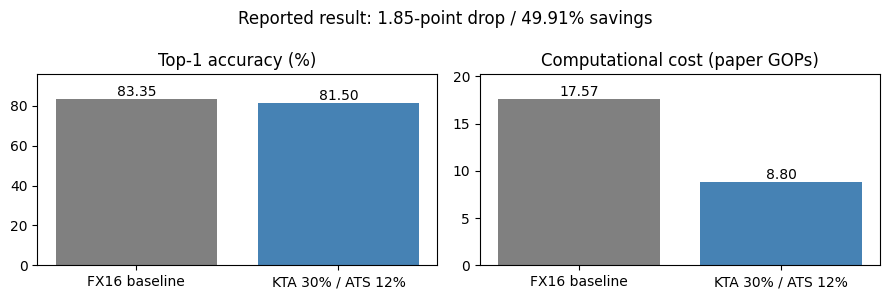

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
labels = ['FX16 baseline', 'KTA 30% / ATS 12%']
for ax, values, title in [(axes[0], [83.35, 81.50], 'Top-1 accuracy (%)'), (axes[1], [17.571, 8.80], 'Computational cost (paper GOPs)')]:
    bars = ax.bar(labels, values, color=['gray', 'steelblue'])
    ax.bar_label(bars, fmt='%.2f')
    ax.set_title(title)
    ax.set_ylim(0, max(values) * 1.15)
fig.suptitle('Reported result: 1.85-point drop / 49.91% savings')
fig.tight_layout()
plt.show()

The displayed costs are rounded paper values; recalculating savings from them may differ slightly from the reported 49.91%. The saved log verifies accuracy, not GOPs.

## Optional full evaluation
Install the repository with `pip install -e .`. Set the paths below and change `RUN_EVALUATION` to `True`. Leave `MAX_IMAGES=None` to evaluate the entire supplied set. For a paper comparison, supply the original 10,000-image manifest and checkpoint; another subset constitutes a different experiment.

In [4]:
RUN_EVALUATION = False
DATA = Path('/path/to/imagenet/val')
LABELS = Path('/path/to/imagenet_class_index.json')
CHECKPOINT = None  # Path('/path/to/original_state_dict.pth')
MANIFEST = None  # Path('/path/to/original_10000_image_paths.txt')
MAX_IMAGES = None
OUTPUT = ROOT / 'runs/vit_base_30_12.json'

In [5]:
if RUN_EVALUATION:
    assert DATA.is_dir() and LABELS.is_file(), 'Set valid data and label paths first'
    command = [sys.executable, str(ROOT / 'scripts/evaluate.py'), '--data', str(DATA), '--labels', str(LABELS), '--model', 'base', '--kta-drop', '0.30', '--ats-drop', '0.12', '--blocks', '3', '4', '5', '6', '7', '8', '--precision', 'fx16', '--tau', 'notebook', '--output', str(OUTPUT)]
    for flag, value in [('--checkpoint', CHECKPOINT), ('--manifest', MANIFEST), ('--max-images', MAX_IMAGES)]:
        if value is not None: command += [flag, str(value)]
    subprocess.run(command, cwd=ROOT, check=True)
    measured = json.loads(OUTPUT.read_text())
    print('New measured accuracy:', measured['accuracy_percent'])
    print('Historical accuracy:', result['historical_accuracy_percent'])
else:
    print('Evaluation disabled. Displayed results above are historical/paper-reported.')

Evaluation disabled. Displayed results above are historical/paper-reported.


## Original experiment
The companion [original experiment notebook](04_original_vit_base_30_12.ipynb) contains the full historical implementation, with portable path configuration and a shortened historical output tail. The result JSON records the original notebook and log hashes.